# ToysAD-8K DS1 Representation and Peer Scores

**Notebook file:** `07.1-toysad8k-ds1-representation-and-peer-scores.ipynb`

This notebook tests the complete frozen-representation and peer-scoring stage on DS1. It uses all 100 scenes, all 20 views, and the three frozen mask routes from Notebook 06.

The main questions are:

1. Can the same object preparation work reliably for every encoder?
2. Do B0, B1, and P1 return stable, label-free rankings?
3. How much do encoder choice and mask route change downstream ranking?
4. Which encoder and scorer should be frozen for the next development stage?

DS1 is the planned 100-scene development screen. It selects a representation configuration for confirmation, but it is not a final test result.

## Saved-output evidence copy

This notebook records the completed run for repository review. Its code and markdown match the clean runnable notebook. Private scene visuals and identifier-bearing output were removed. Safe aggregate tables and charts were retained.

Run stage: `07.1 DS1 representation and peer scores`  
Clean notebook SHA-256: `8a7d3ff9e1cbd057abc4ceb1e03c873105e1e5d3ae7b7a2d1ea0bd4ddcae76c0`  
Downloaded saved-output SHA-256: `cbf9755b08123f58b034a3e830a1169ddf3ff25a6ec8daef37add7581184ef84`


## Experiment map and claim boundary

The notebook has two separate stages.

- **Model-facing stage:** RGB images, masks, crop transforms, frozen encoders, and B0/B1/P1 scores. No anomaly labels, categories, asset groups, or evaluator crosswalks are opened here.
- **Evaluator-only stage:** the completed label-free score package is hash-locked first. Only then are private labels and crosswalks opened to calculate ranking metrics.

The encoder comparison uses the supplied-mask route so proposal and segmentation errors cannot affect model selection. DINOv2-small remains the anchor unless a challenger passes the declared accuracy, confidence, subgroup, and runtime gates.

## Encoder screen

The screen compares DINOv2-small, DINOv2-small with registers, DINOv2-base, DINOv3-small, DINOv3-small-plus, and a ResNet50 control. DINOv2-base is a capacity check, not the default deployment choice. DINOv3-base is optional because it adds another gated capacity run without answering the first lightweight-model question.

DINOv3 access is gated by Meta's licence on Hugging Face. This notebook never accepts that licence automatically. If the account has not accepted it or the `HF_TOKEN` Kaggle Secret is unavailable, DINOv3 is recorded as unavailable and the DINOv2 run continues.

Every encoder receives the same 224 by 224 masked crop. Patch grids may differ by model, so P1 heatmaps are projected through each model's recorded patch grid rather than compared as raw arrays.

The anchor runs on all three mask routes. Challenger encoders run on supplied masks during the screen. This isolates representation quality and avoids repeating the same downstream route experiment for every model. After the encoder is frozen on DS1, the selected encoder will run on all routes.

In [1]:
from __future__ import annotations

from hashlib import sha256
import importlib.util
import json
import os
from pathlib import Path
import subprocess
import sys

from IPython.display import Image as DisplayImage, display
import pandas as pd

NOTEBOOK_NAME = "07.1-toysad8k-ds1-representation-and-peer-scores.ipynb"
EXECUTION_ENVIRONMENT = (
    "kaggle" if Path("/kaggle/working").is_dir() else "local"
)


def find_code_root() -> Path:
    # Locate the attached repository snapshot without relying on one Kaggle slug.
    configured = os.getenv("VPI_CODE_ROOT")
    candidates = [Path(configured).expanduser()] if configured else []
    candidates.extend([Path.cwd(), *Path.cwd().parents])
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.is_dir():
        candidates.extend(path.parents[3] for path in kaggle_input.rglob("visual_encoder.py"))
    for candidate in candidates:
        marker = candidate / "src" / "visual_peer_inspector" / "models" / "visual_encoder.py"
        if marker.is_file():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate the Notebook 07.1 code snapshot.")


CODE_ROOT = find_code_root()
sys.path.insert(0, str(CODE_ROOT / "src"))
print(f"Environment: {EXECUTION_ENVIRONMENT}")
print(f"Notebook: {NOTEBOOK_NAME}")
print(f"Code snapshot folder: {CODE_ROOT.name}")

Environment: kaggle
Notebook: 07.1-toysad8k-ds1-representation-and-peer-scores.ipynb
Code snapshot folder: vpi-code-snapshot


## Runtime dependencies

Kaggle already provides PyTorch. The setup cell installs only the reviewed notebook dependencies that are missing. The installed versions are recorded in the run outputs. Model weights are downloaded from their official Hugging Face repositories and are never written into GitHub outputs.

In [2]:
if EXECUTION_ENVIRONMENT == "kaggle":
    # Avoid replacing Kaggle's CUDA-enabled PyTorch build.
    required = {
        "transformers": "transformers==5.14.1",
        "huggingface_hub": "huggingface-hub==1.26.1",
        "matplotlib": "matplotlib==3.10.8",
        "clearml": "clearml==2.1.10",
    }
    missing = [requirement for module, requirement in required.items() if importlib.util.find_spec(module) is None]
    if missing:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import matplotlib
import numpy as np
torch = None
transformers = None
if importlib.util.find_spec("torch") is not None:
    import torch
if importlib.util.find_spec("transformers") is not None:
    import transformers

runtime_versions = {
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "torch": "not installed" if torch is None else torch.__version__,
    "transformers": "not installed" if transformers is None else transformers.__version__,
    "matplotlib": matplotlib.__version__,
}
display(pd.DataFrame(runtime_versions.items(), columns=["package", "version"]))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.3 MB/s eta 0:00:00


,package,version
0,python,3.12.13
1,numpy,2.0.2
2,torch,2.10.0+cu128
3,transformers,5.0.0
4,matplotlib,3.10.0


## Configuration and private Secrets

The normal Kaggle run uses one GPU. A second T4 does not help unless the notebook starts independent model workers, which this reproducible version does not do.

`HF_TOKEN` is used only for gated DINOv3 access. ClearML is disabled during the GPU run by default. After the output is downloaded and verified, the aggregate-only finaliser can publish the same evidence from the local ClearML configuration. This prevents tracking from delaying inference.

In [3]:
def read_kaggle_secret(name: str) -> str | None:
    if EXECUTION_ENVIRONMENT != "kaggle":
        return os.environ.get(name)
    try:
        from kaggle_secrets import UserSecretsClient

        value = UserSecretsClient().get_secret(name)
        return value if value else None
    except Exception:
        return None


RUN_MODE = os.getenv("VPI_RUN_MODE", "model_evidence")
if RUN_MODE not in {"model_evidence", "contract_test"}:
    raise ValueError("VPI_RUN_MODE must be model_evidence or contract_test")

default_encoders = [
    "dinov2_small",
    "dinov2_small_registers",
    "dinov3_small",
    "dinov3_small_plus",
    "dinov2_base",
    "resnet50_control",
]
if os.getenv("VPI_RUN_CAPACITY_CONFIRMATION", "0") == "1":
    default_encoders.append("dinov3_base")
ENCODER_KEYS = (
    ["contract_encoder"]
    if RUN_MODE == "contract_test"
    else [value.strip() for value in os.getenv("VPI_ENCODERS", ",".join(default_encoders)).split(",") if value.strip()]
)
DEVICE = (
    "cuda"
    if torch is not None and torch.cuda.is_available() and RUN_MODE == "model_evidence"
    else "cpu"
)
ENCODER_BATCH_SIZE = int(os.getenv("VPI_ENCODER_BATCH_SIZE", "32"))
HF_TOKEN = read_kaggle_secret("HF_TOKEN")

if RUN_MODE == "model_evidence" and (torch is None or transformers is None):
    raise RuntimeError("The model-evidence run requires torch and transformers.")
if RUN_MODE == "model_evidence" and DEVICE != "cuda":
    raise RuntimeError("The model-evidence run requires a Kaggle GPU.")

configuration_table = pd.DataFrame(
    {
        "setting": ["run mode", "device", "encoder batch size", "encoders", "DINOv3 token available"],
        "value": [RUN_MODE, DEVICE, ENCODER_BATCH_SIZE, ", ".join(ENCODER_KEYS), bool(HF_TOKEN)],
    }
)
display(configuration_table)

,setting,value
0,run mode,model_evidence
1,device,cuda
2,encoder batch size,32
3,encoders,"dinov2_small, dinov2_small_registers, dinov3_s..."
4,DINOv3 token available,False


## Locate and verify the three inputs

The path resolver looks for package records, not account-specific Kaggle folder names. It requires:

- the Notebook 03 opaque RGB package;
- the Notebook 06 label-free mask-route package; and
- the evaluator-only DS1 package.

Every RGB hash and every mask package checksum is checked before inference.

In [4]:
def locate_package(variable: str, predicate, required_paths: tuple[str, ...]) -> Path:
    configured = os.getenv(variable)
    candidates = [Path(configured).expanduser()] if configured else []
    if Path("/kaggle/input").is_dir():
        candidates.extend(path.parent for path in Path("/kaggle/input").rglob("package_record.json"))
    for candidate in candidates:
        record_path = candidate / "package_record.json"
        if not record_path.is_file():
            continue
        try:
            record = json.loads(record_path.read_text(encoding="utf-8"))
        except Exception:
            continue
        if predicate(record) and all((candidate / relative).exists() for relative in required_paths):
            return candidate.resolve()
    raise FileNotFoundError(f"Could not locate required package: {variable}")


RGB_ROOT = locate_package(
    "VPI_RGB_ROOT",
    lambda record: record.get("release_id") == "toysad8k-train-2000-v2"
    and record.get("image_count") == 2000
    and record.get("all_checks_passed") is True
    and "content_checksums_sha256" in record
    and "media_mode" in record,
    ("neutral_corpus_manifest.jsonl", "content_checksums.sha256", "media"),
)
MASK_ROUTE_ROOT = locate_package(
    "VPI_MASK_ROUTE_ROOT",
    lambda record: record.get("package_kind") == "toysad8k-ds1-model-safe-mask-routes",
    ("mask_routes.jsonl",),
)
EVALUATOR_ROOT = locate_package(
    "VPI_EVALUATOR_ROOT",
    lambda record: record.get("package_kind") == "toysad8k-ds1-mask-evaluator",
    ("reference_manifest.jsonl", "evaluator_crosswalk.jsonl", "usage_policy.json"),
)
default_output = (
    Path("/kaggle/working/toysad8k_ds1_representation_peer_scores")
    if EXECUTION_ENVIRONMENT == "kaggle"
    else CODE_ROOT / ".local" / "runs" / "notebook07_1"
)
OUTPUT_ROOT = Path(os.getenv("VPI_OUTPUT_ROOT", str(default_output))).expanduser().resolve()

from visual_peer_inspector.data.representation_package_ds1 import load_representation_candidates

candidate_groups, input_audit = load_representation_candidates(RGB_ROOT, MASK_ROUTE_ROOT)
display(pd.DataFrame([input_audit.to_dict()]))
print(f"RGB package folder: {RGB_ROOT.name}")
print(f"Mask-route package folder: {MASK_ROUTE_ROOT.name}")
print(f"Evaluator package folder: {EVALUATOR_ROOT.name}")
print(f"Output folder: {OUTPUT_ROOT}")

,scene_count,image_count,route_counts,usable_route_counts,rejected_mask_counts,insufficient_peer_images,membership_sha256,rgb_manifest_sha256,route_manifest_sha256,join_sha256
0,100,2000,"{'automatic_box': 9249, 'reference_box': 7700,...","{'automatic_box': 9193, 'reference_box': 7700,...",{'automatic_box': 56},{'automatic_box': 83},308e2e104448612dc60b5392a5258d97f6d93f52ca553a...,37e2143ae097077f9fa35ffc8a1a281d2e1dfb8a9802dc...,97b0ee754ff92f4482aabed0e2cda39a57561bfd1fe880...,9cf74671887ed60855a0e0304da8745dda6e29bd77488c...


RGB package folder: vpi-toysad-ds1-screen100-model-input
Mask-route package folder: model_input
Evaluator package folder: vpi-toysad-ds1-mask-evaluator
Output folder: /kaggle/working/toysad8k_ds1_representation_peer_scores


## Coverage before scoring

Peer comparison requires at least three candidates in a view. The supplied and reference routes have complete object coverage. The automatic route contains a small number of one-object or two-object views. Those views are recorded as `insufficient_peers`; they are not dropped and they are not given invented scores.

In [5]:
coverage_rows = []
for route in ("supplied_mask", "reference_box", "automatic_box"):
    counts = [len(values) for (_scene, _view, current_route), values in candidate_groups.items() if current_route == route]
    coverage_rows.append(
        {
            "route": route,
            "images": len(counts),
            "candidates": sum(counts),
            "minimum candidates": min(counts),
            "maximum candidates": max(counts),
            "rankable images": sum(value >= 3 for value in counts),
            "insufficient-peer images": sum(value < 3 for value in counts),
        }
    )
display(pd.DataFrame(coverage_rows))

,route,images,candidates,minimum candidates,maximum candidates,rankable images,insufficient-peer images
0,supplied_mask,2000,7700,3,5,2000,0
1,reference_box,2000,7700,3,5,2000,0
2,automatic_box,2000,9193,1,294,1917,83


## Common crop preparation

Each route uses its own frozen mask, but every encoder sees the same geometric preparation:

1. keep only the masked object;
2. replace background with RGB `(238, 241, 245)`;
3. add 15 percent square padding;
4. resize once to 224 by 224; and
5. mark patches as valid when foreground covers at least 50 percent of the patch.

If a valid non-empty object is smaller than every patch, P1 keeps the single patch with the highest foreground coverage. The runtime table records how often this fallback is used. Empty masks and masks with fewer than four foreground pixels are recorded as unusable coverage and are not sent to an encoder.

The panel below is diagnostic evidence. It is private because it contains RGB objects and route masks.

In [6]:
import matplotlib.pyplot as plt
from PIL import Image

from visual_peer_inspector.representation.crops import CropConfiguration, prepare_masked_crop

crop_configuration = CropConfiguration()
first_scene, first_view = sorted({(scene, view) for scene, view, _route in candidate_groups})[0]
figure, axes = plt.subplots(3, 3, figsize=(8, 8))
for row_index, route in enumerate(("supplied_mask", "reference_box", "automatic_box")):
    examples = candidate_groups[(first_scene, first_view, route)][:3]
    rgb = Image.open(examples[0].image_path).convert("RGB")
    for column_index, candidate in enumerate(examples):
        prepared = prepare_masked_crop(rgb, candidate.mask_rle, configuration=crop_configuration)
        axes[row_index, column_index].imshow(prepared.rgb)
        axes[row_index, column_index].set_title(f"{route}\n{candidate.prompt_key}")
        axes[row_index, column_index].axis("off")
figure.suptitle("Common prepared crops across the three routes")
figure.tight_layout()
plt.show()

<Figure size 800x800 with 9 Axes>

## Model registry and decision roles

The lightweight candidates form the core screen. Base models are confirmation checks only. ResNet50 provides a non-ViT global-feature control and does not enter P1.

The notebook resolves each Hugging Face model to an immutable revision before loading it. Register tokens are removed before spatial patch scoring because they do not correspond to image locations.

In [7]:
from visual_peer_inspector.models.visual_encoder import encoder_registry_rows

registry = pd.DataFrame(encoder_registry_rows())
display(
    registry[
        ["key", "family", "model_id", "screen_stage", "parameters_millions", "supports_patches", "gated"]
    ]
)

,key,family,model_id,screen_stage,parameters_millions,supports_patches,gated
0,dinov2_small,DINOv2,facebook/dinov2-small,core,21,True,False
1,dinov2_small_registers,DINOv2,facebook/dinov2-with-registers-small,core,21,True,False
2,dinov3_small,DINOv3,facebook/dinov3-vits16-pretrain-lvd1689m,core,21,True,True
3,dinov3_small_plus,DINOv3,facebook/dinov3-vits16plus-pretrain-lvd1689m,core,29,True,True
4,dinov2_base,DINOv2,facebook/dinov2-base,confirmation,86,True,False
5,dinov3_base,DINOv3,facebook/dinov3-vitb16-pretrain-lvd1689m,confirmation,86,True,True
6,resnet50_control,ResNet,microsoft/resnet-50,control,26,False,False


## B0, B1, and P1 definitions

- **B0:** cosine distance from one object's global feature to the normalized leave-one-out peer mean.
- **B1:** median cosine distance from one object's global feature to every other object in the view.
- **P1:** local patch mismatch. Each valid patch finds its nearest peer patch. The largest 10 percent of directed distances form a symmetric pair distance, and the object score is the median across peers.

P1 heatmaps are coarse feature-mismatch evidence. They are not segmentation masks and must not be described as exact defect boundaries.

Shape and layout scores are reported separately. Notebook 07.1 does not tune an appearance-geometry fusion weight.

## Stage 1: frozen feature extraction and label-free scores

The workflow checks one batch twice before the full run. It records feature dimensions, patch grids, repeatability, runtime, peak GPU memory, and private cache size. Results are saved scene by scene, so a stopped run can resume completed scene shards.

This cell does not open the evaluator package.

In [8]:
from visual_peer_inspector.workflows.representation_ds1 import (
    run_label_free_ds1,
    verify_artifact_manifest,
)

label_free_record_path = OUTPUT_ROOT / "safe" / "label_free_run_record.json"
if label_free_record_path.is_file():
    verify_artifact_manifest(OUTPUT_ROOT / "model_input")
    label_free_record = json.loads(label_free_record_path.read_text(encoding="utf-8"))
    print("Reused the verified label-free score package.")
else:
    label_free_record = run_label_free_ds1(
        rgb_root=RGB_ROOT,
        mask_route_root=MASK_ROUTE_ROOT,
        output_root=OUTPUT_ROOT,
        encoder_keys=ENCODER_KEYS,
        device=DEVICE,
        hf_token=HF_TOKEN,
        run_mode=RUN_MODE,
        encoder_batch_size=ENCODER_BATCH_SIZE,
    )
display(pd.DataFrame([label_free_record]))

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

dinov2_small: completed 1/100 scenes
dinov2_small: completed 10/100 scenes
dinov2_small: completed 20/100 scenes
dinov2_small: completed 30/100 scenes
dinov2_small: completed 40/100 scenes
dinov2_small: completed 50/100 scenes
dinov2_small: completed 60/100 scenes
dinov2_small: completed 70/100 scenes
dinov2_small: completed 80/100 scenes
dinov2_small: completed 90/100 scenes
dinov2_small: completed 100/100 scenes


config.json: 0.00B [00:00, ?B/s]

...

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/318 [00:00<?, ?it/s]

ResNetModel LOAD REPORT from: microsoft/resnet-50
Key                 | Status     |  |
--------------------+------------+--+-
classifier.1.weight | UNEXPECTED |  |
classifier.1.bias   | UNEXPECTED |  |

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


resnet50_control: completed 1/100 scenes
resnet50_control: completed 10/100 scenes
resnet50_control: completed 20/100 scenes
resnet50_control: completed 30/100 scenes
resnet50_control: completed 40/100 scenes
resnet50_control: completed 50/100 scenes
resnet50_control: completed 60/100 scenes
resnet50_control: completed 70/100 scenes
resnet50_control: completed 80/100 scenes
resnet50_control: completed 90/100 scenes
resnet50_control: completed 100/100 scenes


,schema_version,stage,status,run_mode,available_encoder_count,requested_encoder_count,score_package_sha256,configuration_sha256,evaluator_opened
0,1,ds1_representation_and_peer_scores,label_free_scores_complete,model_evidence,4,6,de8bbecc81409d64d8f629559c21db9645a9493e7106d1...,f730cab31f4ed54c23750eeed9e4749246225bb76acf09...,False


## Encoder availability and repeatability

Unavailable gated models remain visible in this table with a short reason. They are never silently replaced. Missing DINOv3 access does not invalidate the DINOv2 engineering run, but it leaves the DINOv3 comparison incomplete. A model must return finite, unit-normalized global features and pass the repeated-batch check before its scene shards are accepted.

In [9]:
availability = pd.read_csv(OUTPUT_ROOT / "safe" / "encoder_availability.csv")
runtime = pd.read_csv(OUTPUT_ROOT / "safe" / "runtime_summary.csv")
display(availability)
display(runtime)

,encoder_key,status,model_id,resolved_revision,family,screen_stage,gated,reason,feature_dimension,patch_grid_size,repeat_minimum_cosine,repeat_maximum_absolute_delta,repeatability_passed,peak_gpu_memory_bytes,route_scope
0,dinov2_small,available,facebook/dinov2-small,ed25f3a31f01632728cabb09d1542f84ab7b0056,DINOv2,core,False,NaN,384.0,16.0,1.0,0.0,True,293035520,supplied_mask+reference_box+automatic_box
1,dinov2_small_registers,available,facebook/dinov2-with-registers-small,0d9846e56b43a21fa46d7f3f5070f0506a5795a9,DINOv2,core,False,NaN,384.0,16.0,1.0,0.0,True,293083648,supplied_mask
2,dinov3_small,unavailable,facebook/dinov3-vits16-pretrain-lvd1689m,NaN,DINOv3,core,True,OSError: gated model access or load failed,NaN,NaN,NaN,NaN,False,0,NaN
3,dinov3_small_plus,unavailable,facebook/dinov3-vits16plus-pretrain-lvd1689m,NaN,DINOv3,core,True,OSError: gated model access or load failed,NaN,NaN,NaN,NaN,False,0,NaN
4,dinov2_base,available,facebook/dinov2-base,f9e44c814b77203eaa57a6bdbbd535f21ede1415,DINOv2,confirmation,False,NaN,768.0,16.0,1.0,0.0,True,821083136,supplied_mask
5,resnet50_control,available,microsoft/resnet-50,34c2154c194f829b11125337b98c8f5f9965ff19,ResNet,control,False,NaN,2048.0,NaN,1.0,0.0,True,307453952,supplied_mask


,encoder_key,scene_count,candidate_count,runtime_seconds,milliseconds_per_candidate,resumed_scene_count,patch_fallback_candidate_count,cache_bytes,peak_gpu_memory_bytes
0,dinov2_small,100,24593,297.030239,12.077837,0,59,20092214,293035520
1,dinov2_small_registers,100,7700,88.625042,11.509746,0,0,7025405,293083648
2,dinov2_base,100,7700,116.280859,15.101410,0,0,12491414,821083136
3,resnet50_control,100,7700,55.719962,7.236359,0,0,21719657,307453952


## Feature cache and private diagnostics

The cache stores global features and coarse P1 heatmaps in private Kaggle output. Patch feature arrays are temporary and are not retained. The cache is excluded from GitHub and ClearML.

The next panel shows the highest mean P1 mismatch examples from each available ViT. It is for visual checking only and remains private.

In [10]:
cache_summary = json.loads((OUTPUT_ROOT / "safe" / "cache_summary.json").read_text(encoding="utf-8"))
display(pd.DataFrame(cache_summary.items(), columns=["measure", "value"]))

for panel in sorted((OUTPUT_ROOT / "private" / "figures").glob("p1_heatmap_examples_*.png")):
    print(panel.name)
    display(DisplayImage(filename=str(panel)))

,measure,value
0,cache_is_private,True
1,configuration_sha256,f730cab31f4ed54c23750eeed9e4749246225bb76acf09...
2,global_features_retained,True
3,p1_heatmaps_retained,True
4,patch_features_retained,False
5,resumed_scene_shard_count,0
6,scene_shard_count,400


p1_heatmap_examples_dinov2_base.png


<IPython.core.display.Image object>

p1_heatmap_examples_dinov2_small.png


<IPython.core.display.Image object>

p1_heatmap_examples_dinov2_small_registers.png


<IPython.core.display.Image object>

## Stage 2: evaluator-only ranking metrics

The score package manifest and package record are verified before this stage starts. The evaluator then maps route-local candidates to randomized object identities and labels.

For the automatic route, unmatched proposals remain negative candidates and missed anomalous objects remain in the AP denominator. A top-ranked unmatched proposal is a Top-1 failure. Views with fewer than three proposals reduce reported coverage.

In [11]:
from visual_peer_inspector.workflows.representation_ds1 import run_private_ds1_evaluation

evaluation_record_path = OUTPUT_ROOT / "safe" / "run_record.json"
if evaluation_record_path.is_file():
    evaluation_record = json.loads(evaluation_record_path.read_text(encoding="utf-8"))
    print("Reused the verified evaluator outputs.")
else:
    evaluation_record = run_private_ds1_evaluation(
        representation_root=OUTPUT_ROOT,
        evaluator_root=EVALUATOR_ROOT,
    )
display(pd.DataFrame([evaluation_record]))

,schema_version,stage,status,run_mode,score_package_sha256,evaluator_opened_after_score_lock,evaluation_row_count,scene_metric_row_count,all_completion_gates_passed,decision,selected_encoder,selected_scorer
0,1,ds1_representation_and_peer_scores,completed,model_evidence,de8bbecc81409d64d8f629559c21db9645a9493e7106d1...,True,45585,2300,True,freeze_encoder_and_scorer_on_ds1,dinov2_small,P1


## Encoder comparison

The primary comparison uses supplied masks and B0. This isolates the frozen visual representation from proposal and segmentation errors. The promotion rule then selects one encoder for confirmation.

,encoder_key,scene_count,top1,reciprocal_rank,average_precision,recall_at_2,exact_set
2,dinov2_small_registers,100,0.4270,0.657517,0.646579,0.63600,0.3490
0,dinov2_base,100,0.4170,0.651983,0.641292,0.63250,0.3425
1,dinov2_small,100,0.4175,0.651767,0.640738,0.62725,0.3380
3,resnet50_control,100,0.3950,0.632633,0.623496,0.59325,0.3190


,encoder_key,route,method,metric,mean,ci_lower,ci_upper,cluster_count,repetitions,seed
0,dinov2_base,supplied_mask,B0,average_precision,0.641292,0.602251,0.684040,27,10000,32040
9,dinov2_small,supplied_mask,B0,average_precision,0.640738,0.599864,0.684915,27,10000,32040
12,dinov2_small_registers,supplied_mask,B0,average_precision,0.646579,0.608172,0.690237,27,10000,32040
21,resnet50_control,supplied_mask,B0,average_precision,0.623496,0.583703,0.669567,27,10000,32040


,comparison_family,candidate_encoder,candidate_route,candidate_method,baseline_encoder,baseline_route,baseline_method,metric,mean_difference,ci_lower,ci_upper,paired_scene_count,cluster_count,repetitions,seed
0,encoder_vs_anchor,dinov2_base,supplied_mask,B0,dinov2_small,supplied_mask,B0,average_precision,0.000554,-0.012096,0.014016,100,27,10000,32040
1,encoder_vs_anchor,dinov2_small_registers,supplied_mask,B0,dinov2_small,supplied_mask,B0,average_precision,0.005842,-0.003400,0.015921,100,27,10000,32040
2,encoder_vs_anchor,resnet50_control,supplied_mask,B0,dinov2_small,supplied_mask,B0,average_precision,-0.017242,-0.030773,-0.003605,100,27,10000,32040


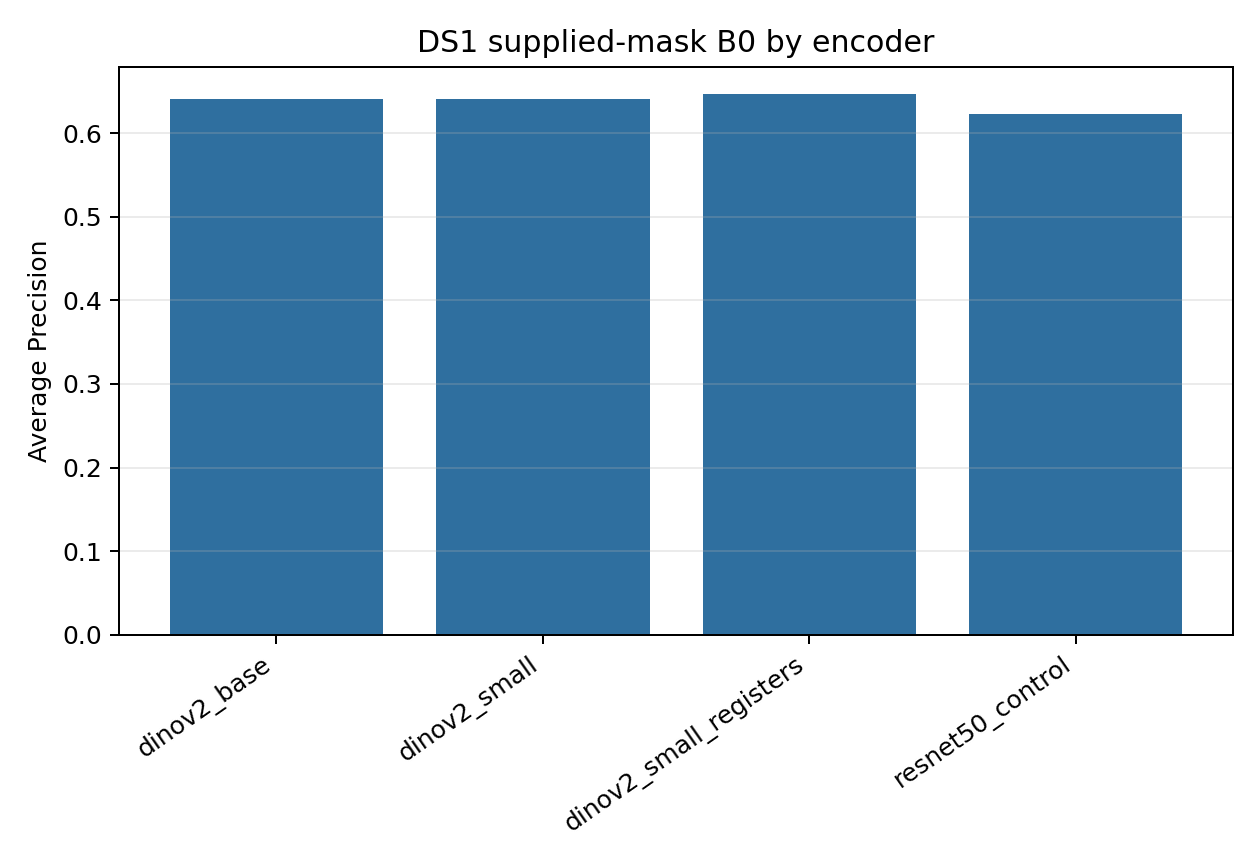

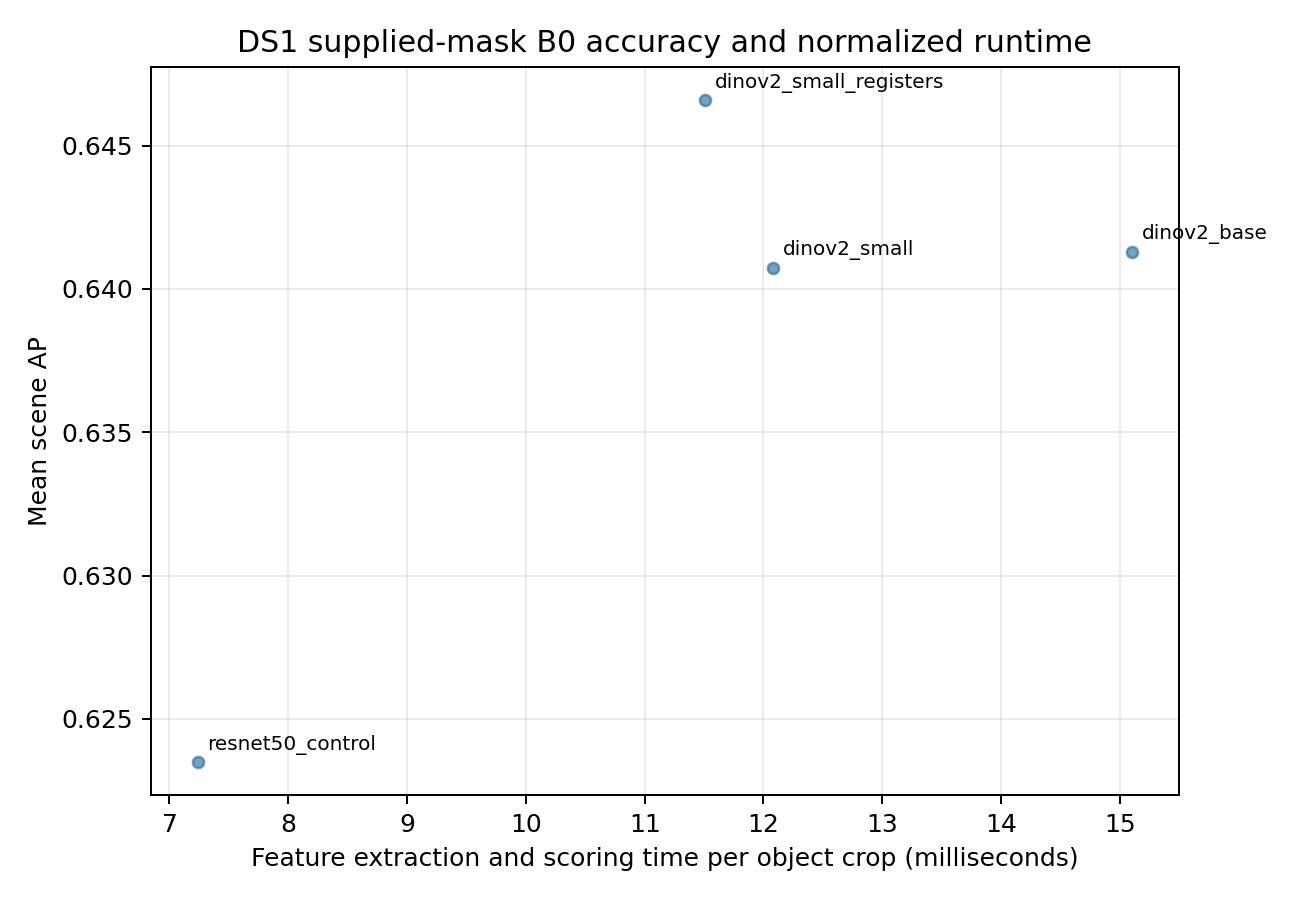

In [12]:
encoder_summary = pd.read_csv(OUTPUT_ROOT / "safe" / "encoder_summary.csv")
intervals = pd.read_csv(OUTPUT_ROOT / "safe" / "clustered_intervals.csv")
paired_differences = pd.read_csv(OUTPUT_ROOT / "safe" / "paired_differences.csv")
display(encoder_summary.sort_values("average_precision", ascending=False))
display(intervals.query("route == 'supplied_mask' and method == 'B0'"))
display(paired_differences.query("comparison_family == 'encoder_vs_anchor'"))
display(DisplayImage(filename=str(OUTPUT_ROOT / "safe" / "figures" / "encoder_b0_scene_ap.png")))
display(DisplayImage(filename=str(OUTPUT_ROOT / "safe" / "figures" / "encoder_efficiency.png")))

## B0, B1, and P1 comparison

This comparison uses the same supplied-mask objects and frozen encoder. It shows whether robust global distances or patch evidence improve ranking over B0. Results are split by one-anomaly and two-anomaly scenes.

,encoder_key,method,scene_count,top1,reciprocal_rank,average_precision,recall_at_2,exact_set
2,dinov2_base,P1,100,0.4670,0.685158,0.675004,0.67100,0.3895
0,dinov2_base,B0,100,0.4170,0.651983,0.641292,0.63250,0.3425
1,dinov2_base,B1,100,0.4100,0.645692,0.633742,0.62000,0.3265
5,dinov2_small,P1,100,0.4600,0.678958,0.667208,0.66350,0.3795
3,dinov2_small,B0,100,0.4175,0.651767,0.640738,0.62725,0.3380
4,dinov2_small,B1,100,0.4115,0.647642,0.637679,0.62275,0.3380
8,dinov2_small_registers,P1,100,0.4505,0.673150,0.661800,0.65750,0.3680
6,dinov2_small_registers,B0,100,0.4270,0.657517,0.646579,0.63600,0.3490
7,dinov2_small_registers,B1,100,0.4185,0.650592,0.638708,0.62050,0.3345
10,geometry,shape_B1,100,0.3060,0.578492,0.568946,0.54200,0.2310


,encoder_key,route,method,anomaly_count,scene_count,top1,reciprocal_rank,average_precision,recall_at_2,exact_set
0,dinov2_base,supplied_mask,B0,1,75,0.397333,0.634867,0.634867,0.679333,0.397333
1,dinov2_base,supplied_mask,B0,2,25,0.476000,0.703333,0.660567,0.492000,0.178000
2,dinov2_base,supplied_mask,B1,1,75,0.384000,0.625700,0.625700,0.669333,0.384000
3,dinov2_base,supplied_mask,B1,2,25,0.488000,0.705667,0.657867,0.472000,0.154000
4,dinov2_base,supplied_mask,P1,1,75,0.455333,0.673267,0.673267,0.724000,0.455333
5,dinov2_base,supplied_mask,P1,2,25,0.502000,0.720833,0.680217,0.512000,0.192000
6,dinov2_small,automatic_box,B0,1,75,0.381141,0.612051,0.612051,0.652364,0.381141
7,dinov2_small,automatic_box,B0,2,25,0.472936,0.693473,0.645288,0.477246,0.167310
8,dinov2_small,automatic_box,B1,1,75,0.375046,0.606409,0.606409,0.638443,0.375046
9,dinov2_small,automatic_box,B1,2,25,0.454947,0.683766,0.638640,0.471363,0.162058


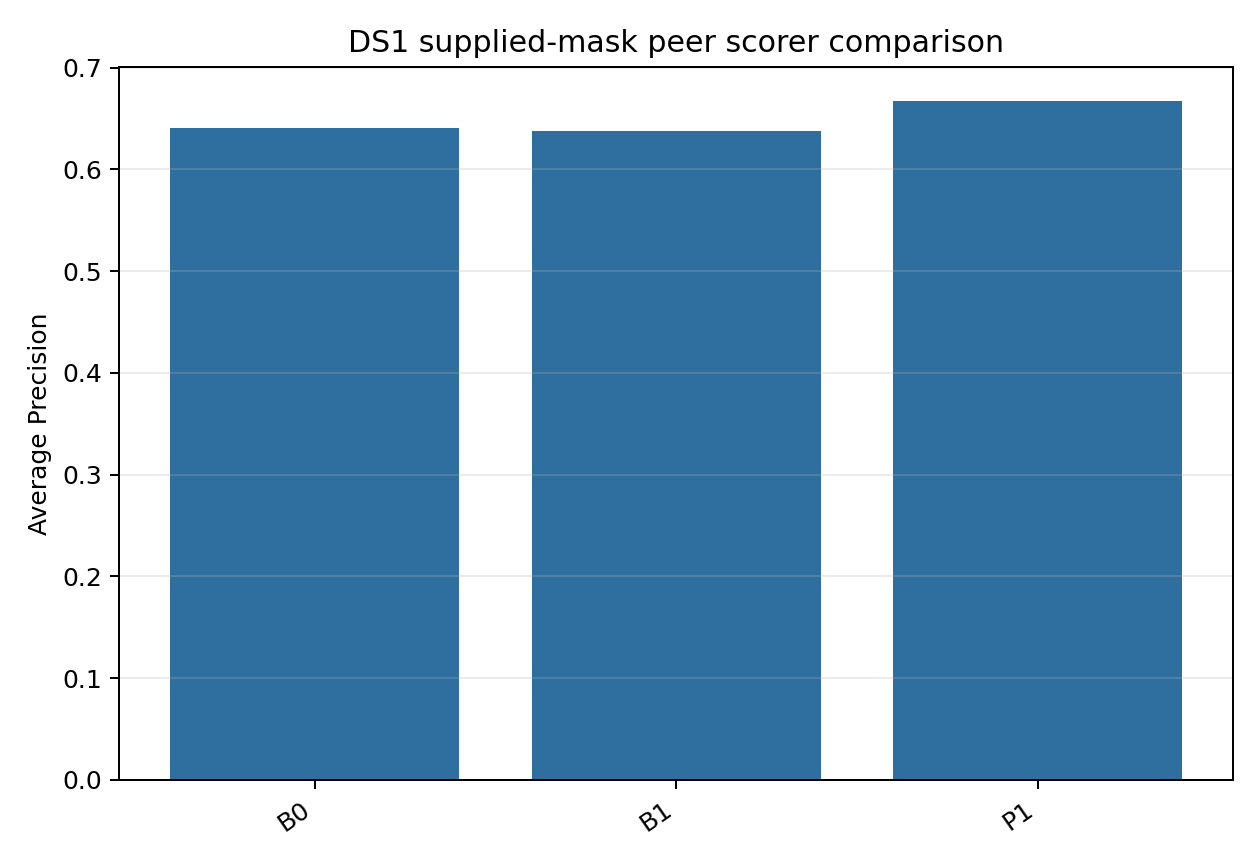

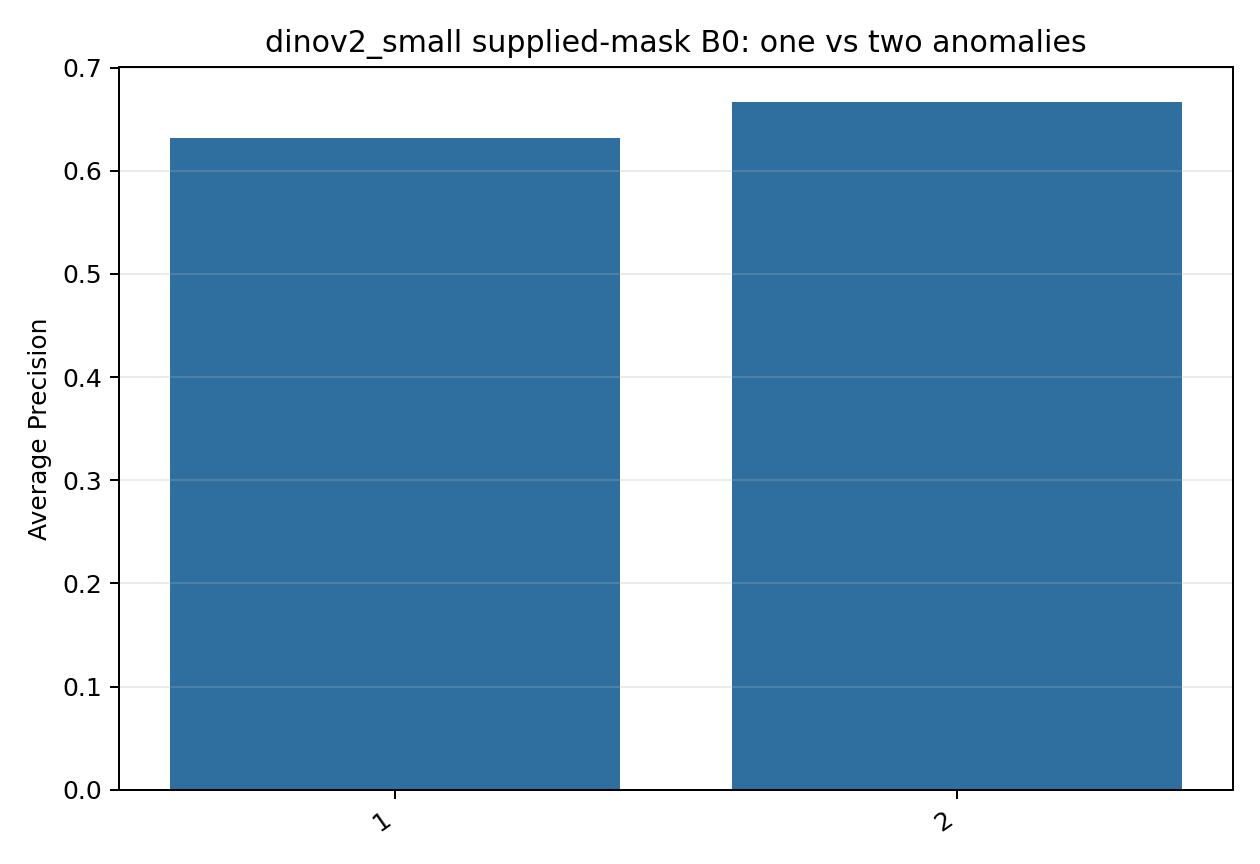

In [13]:
scorer_summary = pd.read_csv(OUTPUT_ROOT / "safe" / "scorer_summary.csv")
scene_type_summary = pd.read_csv(OUTPUT_ROOT / "safe" / "scene_type_summary.csv")
display(scorer_summary.sort_values(["encoder_key", "average_precision"], ascending=[True, False]))
display(scene_type_summary)
display(DisplayImage(filename=str(OUTPUT_ROOT / "safe" / "figures" / "anchor_scorer_comparison.png")))
display(DisplayImage(filename=str(OUTPUT_ROOT / "safe" / "figures" / "one_vs_two_anomaly_scene_ap.png")))

## Route impact and rankable coverage

The route table compares supplied masks, SAM masks prompted by reference boxes, and SAM masks prompted by automatic boxes. These are downstream ranking results, not segmentation IoU results.

,encoder_key,route,method,scene_count,top1,reciprocal_rank,average_precision,recall_at_2,exact_set
0,dinov2_base,supplied_mask,B0,100,0.417000,0.651983,0.641292,0.632500,0.342500
1,dinov2_base,supplied_mask,B1,100,0.410000,0.645692,0.633742,0.620000,0.326500
2,dinov2_base,supplied_mask,P1,100,0.467000,0.685158,0.675004,0.671000,0.389500
3,dinov2_small,automatic_box,B0,100,0.404090,0.632406,0.620360,0.608584,0.327684
4,dinov2_small,automatic_box,B1,100,0.395021,0.625748,0.614467,0.596673,0.321799
5,dinov2_small,automatic_box,P1,100,0.429702,0.647598,0.634003,0.620599,0.343851
6,dinov2_small,reference_box,B0,100,0.419500,0.652483,0.641187,0.625250,0.339000
7,dinov2_small,reference_box,B1,100,0.409000,0.644575,0.633300,0.611500,0.329500
8,dinov2_small,reference_box,P1,100,0.446000,0.668333,0.658092,0.646750,0.367500
9,dinov2_small,supplied_mask,B0,100,0.417500,0.651767,0.640738,0.627250,0.338000


,encoder_key,route,method,status,view_count
0,dinov2_base,supplied_mask,B0,scored,2000
1,dinov2_base,supplied_mask,B1,scored,2000
2,dinov2_base,supplied_mask,P1,scored,2000
3,dinov2_small,automatic_box,B0,insufficient_peers,83
4,dinov2_small,automatic_box,B0,scored,1917
5,dinov2_small,automatic_box,B1,insufficient_peers,83
6,dinov2_small,automatic_box,B1,scored,1917
7,dinov2_small,automatic_box,P1,insufficient_peers,83
8,dinov2_small,automatic_box,P1,scored,1917
9,dinov2_small,reference_box,B0,scored,2000


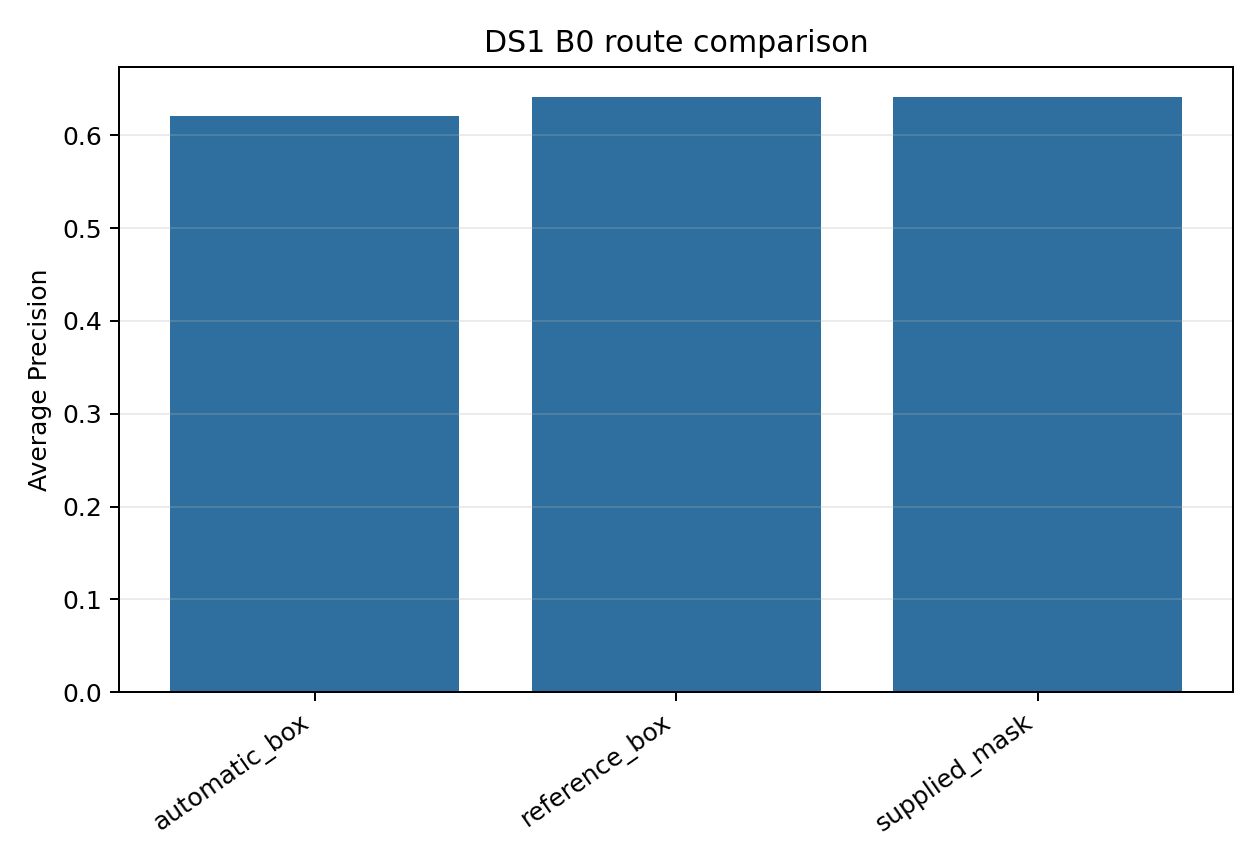

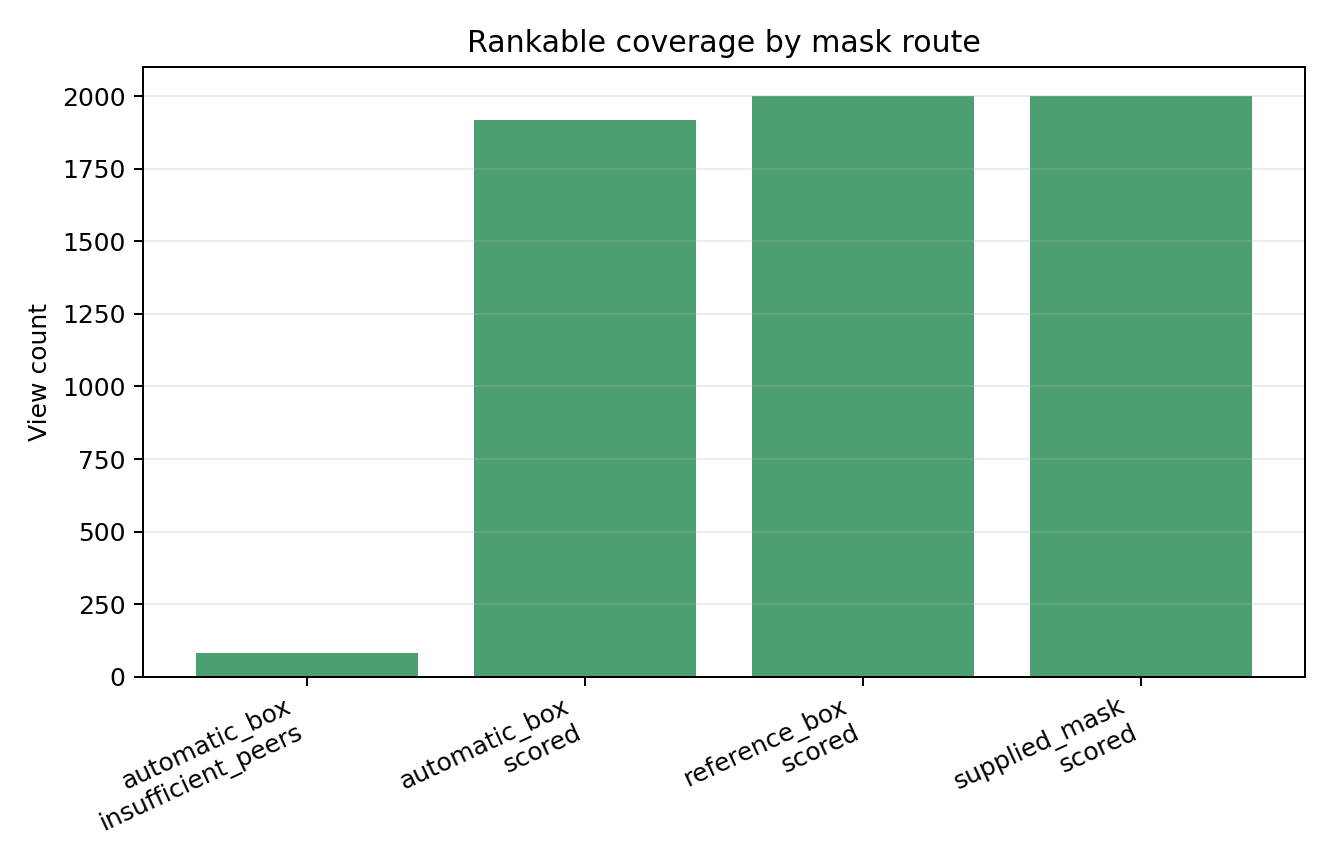

In [14]:
route_summary = pd.read_csv(OUTPUT_ROOT / "safe" / "route_summary.csv")
coverage_summary = pd.read_csv(OUTPUT_ROOT / "safe" / "coverage_summary.csv")
display(route_summary)
display(coverage_summary)
display(DisplayImage(filename=str(OUTPUT_ROOT / "safe" / "figures" / "anchor_route_comparison.png")))
display(DisplayImage(filename=str(OUTPUT_ROOT / "safe" / "figures" / "rankable_coverage.png")))

## Geometry branch and encoder agreement

Shape and layout are kept separate from appearance. This avoids tuning a fusion weight on DS1. The agreement matrix shows how often encoders choose the same most unusual supplied-mask object in a view.

,route,method,scene_count,top1,reciprocal_rank,average_precision,recall_at_2,exact_set
0,automatic_box,layout_B1,100,0.297598,0.552295,0.541206,0.485448,0.218566
1,automatic_box,shape_B1,100,0.302928,0.565816,0.554537,0.532584,0.230562
2,reference_box,layout_B1,100,0.300500,0.564425,0.556287,0.500750,0.228000
3,reference_box,shape_B1,100,0.306000,0.577992,0.568946,0.539500,0.232000
4,supplied_mask,layout_B1,100,0.302000,0.566258,0.556371,0.501500,0.221500
5,supplied_mask,shape_B1,100,0.306000,0.578492,0.568946,0.542000,0.231000


,encoder_a,encoder_b,comparable_view_count,top_candidate_agreement
0,dinov2_base,dinov2_base,2000,1.0000
1,dinov2_base,dinov2_small,2000,0.7450
2,dinov2_base,dinov2_small_registers,2000,0.7365
3,dinov2_base,resnet50_control,2000,0.6375
4,dinov2_small,dinov2_base,2000,0.7450
5,dinov2_small,dinov2_small,2000,1.0000
6,dinov2_small,dinov2_small_registers,2000,0.7940
7,dinov2_small,resnet50_control,2000,0.6555
8,dinov2_small_registers,dinov2_base,2000,0.7365
9,dinov2_small_registers,dinov2_small,2000,0.7940


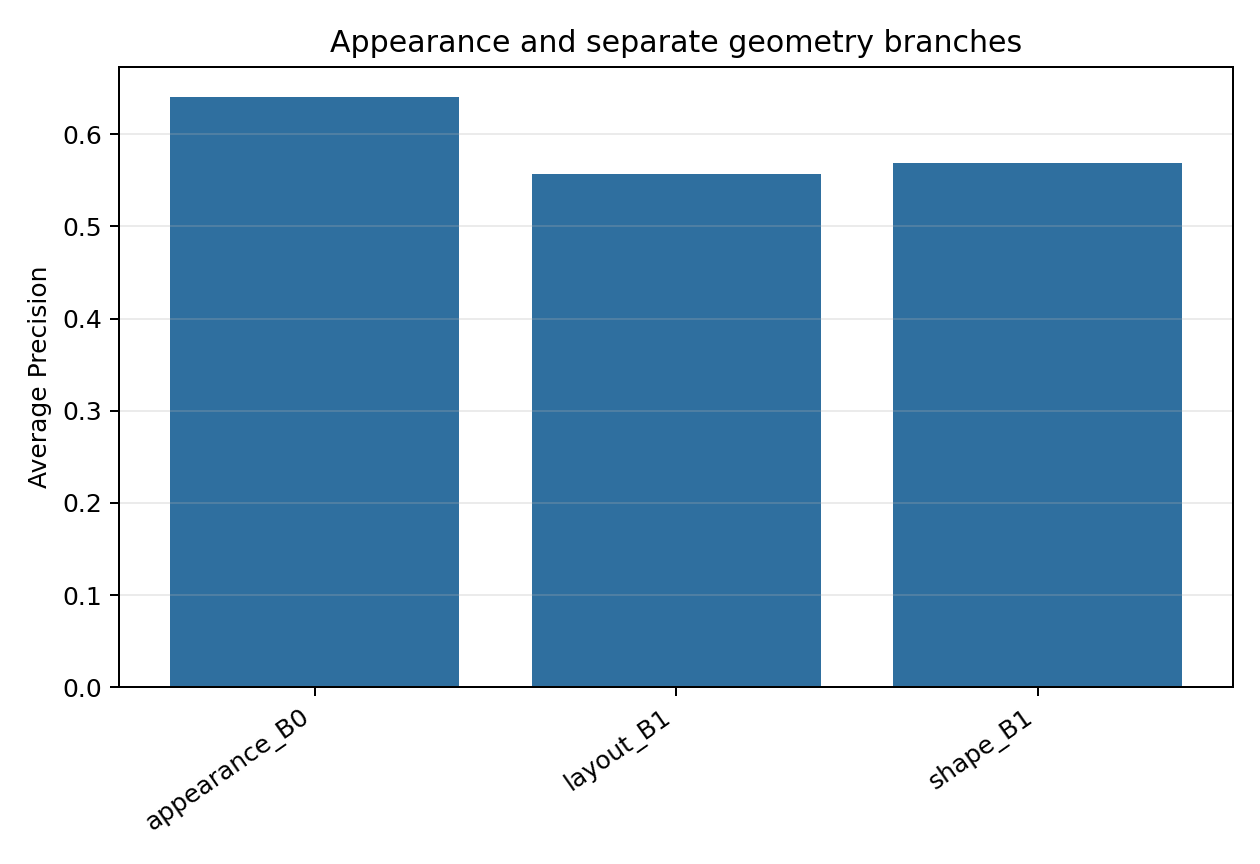

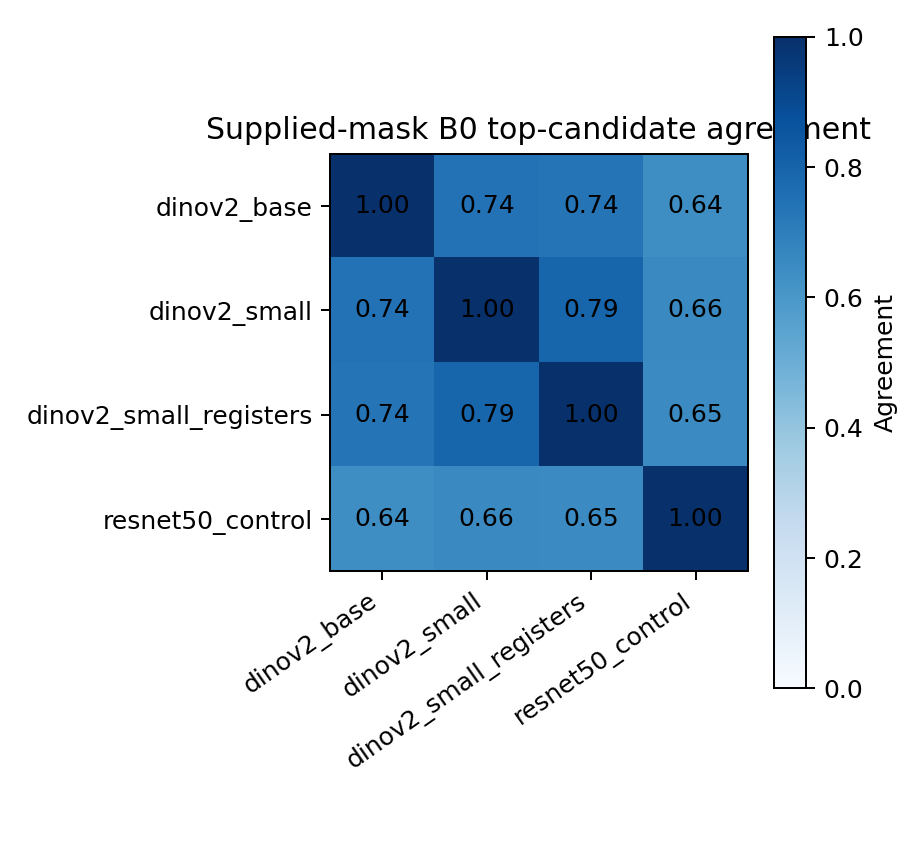

In [15]:
geometry_summary = pd.read_csv(OUTPUT_ROOT / "safe" / "geometry_summary.csv")
agreement = pd.read_csv(OUTPUT_ROOT / "safe" / "model_agreement.csv")
display(geometry_summary)
display(agreement)
display(DisplayImage(filename=str(OUTPUT_ROOT / "safe" / "figures" / "geometry_vs_appearance.png")))
display(DisplayImage(filename=str(OUTPUT_ROOT / "safe" / "figures" / "model_agreement.png")))

## View profile

Views are repeated observations, not independent scenes. Metrics are averaged across eligible views within each scene before dataset aggregation. This table remains useful for finding camera angles that are consistently difficult.

In [16]:
view_summary = pd.read_csv(OUTPUT_ROOT / "safe" / "view_summary.csv")
display(view_summary.sort_values("average_precision").head(30))

,encoder_key,route,method,view_id,scene_count,average_precision,top1
367,geometry,reference_box,shape_B1,V07,100,0.487333,0.150000
407,geometry,supplied_mask,shape_B1,V07,100,0.496500,0.160000
327,geometry,automatic_box,shape_B1,V07,96,0.503877,0.187500
314,geometry,automatic_box,layout_B1,V14,95,0.504123,0.242105
329,geometry,automatic_box,shape_B1,V09,93,0.506183,0.247312
326,geometry,automatic_box,shape_B1,V06,98,0.509439,0.214286
304,geometry,automatic_box,layout_B1,V04,97,0.509708,0.226804
323,geometry,automatic_box,shape_B1,V03,98,0.511224,0.214286
303,geometry,automatic_box,layout_B1,V03,98,0.511310,0.265306
401,geometry,supplied_mask,shape_B1,V01,100,0.519083,0.230000


## Completion gates and decision

Passing this notebook means one encoder and one scorer have been frozen for the next development stage. It does not approve the automatic proposal route or make a final test claim.

In [17]:
completion_gates = pd.read_csv(OUTPUT_ROOT / "safe" / "completion_gates.csv")
decision = json.loads((OUTPUT_ROOT / "safe" / "promotion_decision.json").read_text(encoding="utf-8"))
display(completion_gates)
display(pd.DataFrame([decision]))
if not completion_gates["passed"].astype(bool).all():
    raise RuntimeError("Notebook 07.1 has a failed completion gate.")

,gate,passed
0,score_package_locked_before_evaluator,True
1,labels_absent_from_feature_and_score_generation,True
2,required_ungated_encoder_screen_succeeded,True
3,gated_encoder_access_outcome_recorded,True
4,automatic_route_coverage_reported,True
5,one_and_two_anomaly_metrics_separated,True
6,encoder_and_scorer_selected_for_confirmation,True


,anchor_encoder,anchor_scorer,available_encoders,claim_boundary,decision,dino3_access_result_recorded,encoder_candidates,final_encoder_selected,promotion_rule,route_for_selection,scorer_candidates,selected_encoder,selected_scorer
0,dinov2_small,B0,"[dinov2_small, dinov2_small_registers, dinov2_...",This freezes the representation configuration ...,freeze_encoder_and_scorer_on_ds1,True,"[{'encoder_key': 'dinov2_base', 'gain_over_anc...",True,"{'maximum_anomaly_count_subgroup_loss': 0.03, ...",supplied_mask,"[{'gain_over_b0': 0.0, 'mean_scene_ap': 0.6407...",dinov2_small,P1


## Safe ClearML finalisation

The finaliser runs only after all inference, evaluation, charts, and manifests are complete. On Kaggle it uploads the aggregate tables, charts, configuration hashes, runtime, memory, cache, coverage, and decision evidence after computation has finished.

It rejects RGB images, masks, crops, P1 heatmaps, feature arrays, per-object scores, labels, object IDs, scene IDs, crosswalks, credentials, and absolute paths. A ClearML timeout records a receipt but does not erase the completed model run.

In [18]:
TRACKING_MODE = os.getenv(
    "VPI_TRACKING_MODE",
    "online" if EXECUTION_ENVIRONMENT == "kaggle" else "disabled",
)
tracking_environment = os.environ.copy()
if TRACKING_MODE == "online":
    tracking_credentials = {}
    for name in ("CLEARML_API_ACCESS_KEY", "CLEARML_API_SECRET_KEY"):
        value = read_kaggle_secret(name)
        if value:
            tracking_credentials[name] = value
    if len(tracking_credentials) == 2:
        tracking_environment.update(tracking_credentials)
        tracking_environment.setdefault("CLEARML_API_HOST", "https://api.clear.ml")
        tracking_environment.setdefault("CLEARML_WEB_HOST", "https://app.clear.ml")
        tracking_environment.setdefault("CLEARML_FILES_HOST", "https://files.clear.ml")
    else:
        TRACKING_MODE = "disabled"

receipt = OUTPUT_ROOT / "clearml_receipt.json"
command = [
    sys.executable,
    str(CODE_ROOT / "scripts" / "finalize_ds1_representation_clearml.py"),
    "--safe-root", str(OUTPUT_ROOT / "safe"),
    "--receipt", str(receipt),
    "--mode", TRACKING_MODE,
    "--task-name", "ds1-representation-peer-scores-kaggle-candidate",
    "--tag", "candidate",
    "--tag", "notebook-07-1",
    "--tag", "ds1",
    "--tag", "kaggle",
]
try:
    tracking_process = subprocess.run(
        command,
        env=tracking_environment,
        text=True,
        capture_output=True,
        timeout=240,
    )
    if tracking_process.returncode != 0:
        print(tracking_process.stderr[-1000:])
except subprocess.TimeoutExpired:
    print("ClearML finalisation timed out after the completed model run.")
if not receipt.is_file():
    receipt.write_text(
        json.dumps({"status": "not_recorded", "task_id": None}) + "\n",
        encoding="utf-8",
    )
tracking_receipt = json.loads(receipt.read_text(encoding="utf-8"))
display(pd.DataFrame([tracking_receipt]))

,mode,run_status,safe_manifest_sha256,schema_version,stage,status,task_id
0,disabled,completed,eb1bbc251651e3edc97a4661fe8d66f7476d75d87b739f...,1,notebook_07_1_clearml_finalisation,disabled,None


## Final artifact verification

The same verifier is used locally after downloading Kaggle output. It checks all four artifact manifests, the completion record, tables, chart integrity, and the declared run mode.

In [19]:
verify_command = [
    sys.executable,
    str(CODE_ROOT / "scripts" / "verify_ds1_representation.py"),
    "--output-root", str(OUTPUT_ROOT),
]
if RUN_MODE == "model_evidence":
    verify_command.append("--require-model-evidence")
verified = subprocess.run(verify_command, check=True, text=True, capture_output=True)
verification_summary = json.loads(verified.stdout)
display(pd.DataFrame([verification_summary]))

,artifact_counts,available_encoders,evaluation_row_count,run_mode,safe_chart_count,score_row_count,status
0,"{'cache': 800, 'model_input': 3, 'private': 41...","[dinov2_small, dinov2_small_registers, dinov2_...",45585,model_evidence,8,192265,verified


## Next stage

Notebook 07.1 is complete when the model-evidence run passes and the downloaded output verifies locally.

The next work is:

1. carry the selected encoder and scorer into the untouched 300-scene confirmation cohort;
2. keep the supplied-mask and reference-box routes as the main representation paths;
3. treat the automatic-box route as diagnostic until proposal refinement passes its gates; and
4. start Notebook 08 only after the configuration is confirmed.

Cross-view fusion is deliberately absent here because route prompt keys are local to each image and are not stable object identities.